# Online Shoppers Purchasing Intention: что предсказывает покупку

**Датасет:** [Online Shoppers Purchasing Intention](https://www.kaggle.com/datasets/imakash3011/online-shoppers-purchasing-intention-dataset) — 12 330 сессий интернет-магазина, 18 признаков, цель `Revenue` (закончилась ли сессия покупкой).

**Задача:** бинарная классификация с дисбалансом классов.

**Метрики:** главная — PR-AUC (average precision) и F1 по классу «покупка»; ROC-AUC, precision, recall — дополнительно; accuracy — только для сравнения

**План:** гипотезы → EDA → подготовка данных → базовые модели → эксперименты по гипотезам → подбор гиперпараметров → финальная оценка на test → выводы.

## Гипотезы (сформулированы до экспериментов)

**Гипотеза 1. Accuracy обманывает** Модель «никто не купит» получит accuracy ≥ 0.8, но F1 по покупкам у неё 0, а обученная модель поднимет accuracy лишь ненамного.

**Гипотеза 2. PageValues — главный признак**: PageValues — самый важный признак, и модель, обученная только на нём, уже даёт ROC-AUC ≥ 0.85.

**Гипотеза 3. Хватит 8 признаков** Если оставить 8 лучших признаков (SelectKBest), ROC-AUC упадёт меньше чем на 0.01.

**Гипотеза 4. Бустинг и Random Forest лучше логрегрессии** По PR-AUC бустинг или Random Forest обгонят логистическую регрессию минимум на 0.03, потому что зависимости нелинейны.

**Гипотеза 5. Лучшая глубина дерева по CV лежит в 3–8.** При глубине ≥ 15 CV ROC-AUC падает на 0.03 и более от пика, а train ROC-AUC выше 0.98.

## 1. Импорты и настройки

In [3]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform, randint
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             accuracy_score, average_precision_score, f1_score, make_scorer,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold, cross_val_predict,
                                     cross_val_score, cross_validate, train_test_split, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', lambda v: f'{v:.3f}')

## 2. Данные и EDA

In [6]:
DATA_PATH = 'C:\\Users\\Bylbik\\online_shoppers_intention.csv' 
df = pd.read_csv(DATA_PATH)
print('Размер:', df.shape)
display(df.head())
df.info()

Размер: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.000,0,0.000,1,0.000,0.200,0.200,0.000,0.000,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.000,0,0.000,2,64.000,0.000,0.100,0.000,0.000,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.000,0,0.000,1,0.000,0.200,0.200,0.000,0.000,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.000,0,0.000,2,2.667,0.050,0.140,0.000,0.000,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.000,0,0.000,10,627.500,0.020,0.050,0.000,0.000,Feb,3,3,1,4,Returning_Visitor,True,False


<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [7]:
na = df.isna().sum()
print('Пропуски (только столбцы, где они есть):')
print(na[na > 0] if na.any() else 'пропусков нет')
print('Полных дубликатов строк:', df.duplicated().sum())
display(df.describe().T)

Пропуски (только столбцы, где они есть):
пропусков нет
Полных дубликатов строк: 125


,count,mean,std,min,25%,50%,75%,max
Administrative,12330.000,2.315,3.322,0.000,0.000,1.000,4.000,27.000
Administrative_Duration,12330.000,80.819,176.779,0.000,0.000,7.500,93.256,3398.750
Informational,12330.000,0.504,1.270,0.000,0.000,0.000,0.000,24.000
Informational_Duration,12330.000,34.472,140.749,0.000,0.000,0.000,0.000,2549.375
ProductRelated,12330.000,31.731,44.476,0.000,7.000,18.000,38.000,705.000
ProductRelated_Duration,12330.000,1194.746,1913.669,0.000,184.137,598.937,1464.157,63973.522
BounceRates,12330.000,0.022,0.048,0.000,0.000,0.003,0.017,0.200
ExitRates,12330.000,0.043,0.049,0.000,0.014,0.025,0.050,0.200
PageValues,12330.000,5.889,18.568,0.000,0.000,0.000,0.000,361.764
SpecialDay,12330.000,0.061,0.199,0.000,0.000,0.000,0.000,1.000


Revenue
False    10422
True      1908
Name: count, dtype: int64
Revenue
False   0.845
True    0.155
Name: proportion, dtype: float64


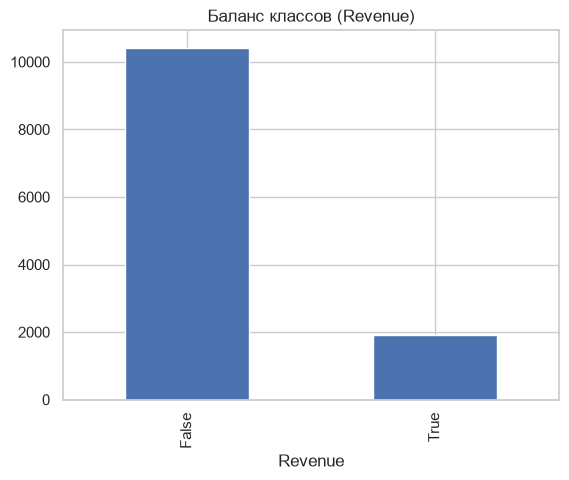

In [8]:
TARGET = 'Revenue'
print(df[TARGET].value_counts())
print(df[TARGET].value_counts(normalize=True).round(3))
df[TARGET].value_counts().plot(kind='bar', title='Баланс классов (Revenue)')
plt.show()

,доля нулей,асимметрия
Administrative,0.468,1.960
Informational,0.787,4.036
ProductRelated,0.003,4.342
Administrative_Duration,0.479,5.616
Informational_Duration,0.805,7.579
ProductRelated_Duration,0.061,7.263
BounceRates,0.448,2.948
ExitRates,0.006,2.149
PageValues,0.779,6.383
SpecialDay,0.899,3.303


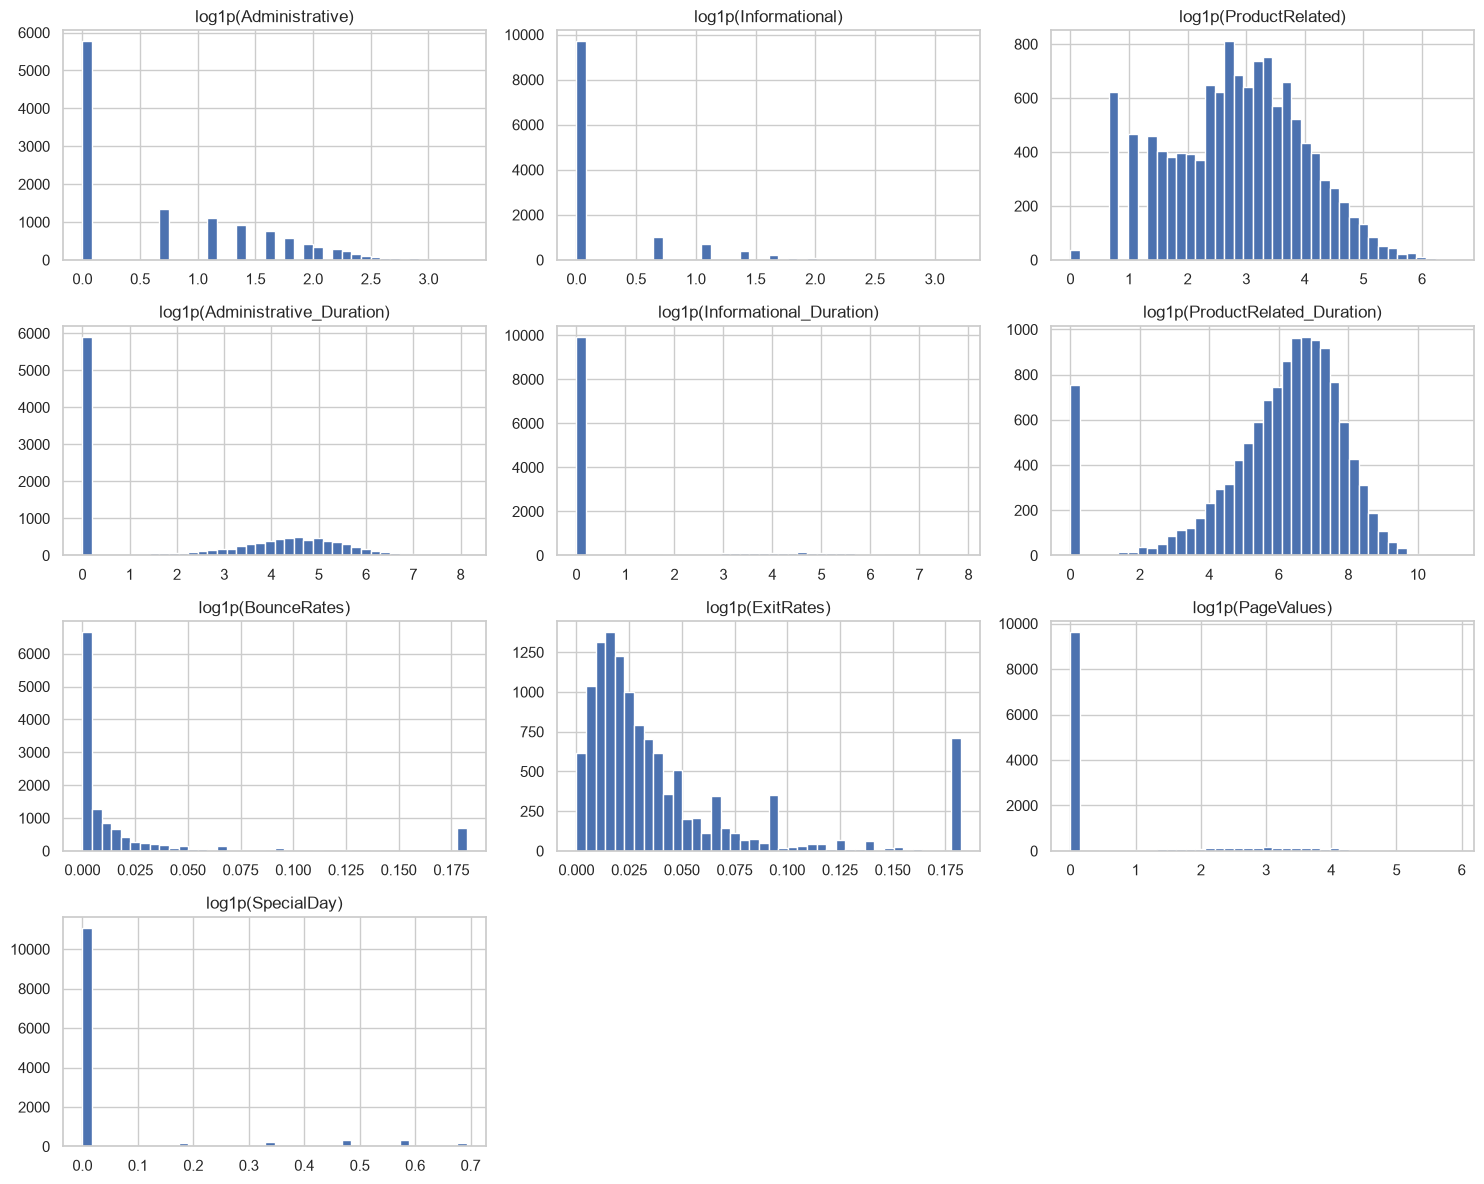

In [9]:
# Группы признаков (используем дальше везде)
count_cols = ['Administrative', 'Informational', 'ProductRelated']                              # число просмотренных страниц
dur_cols   = ['Administrative_Duration', 'Informational_Duration', 'ProductRelated_Duration']   # время на них
rate_cols  = ['BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
num_cols   = count_cols + dur_cols + rate_cols
cat_cols   = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType']   # коды — это категории, не числа
bin_cols   = ['Weekend']

zeros = (df[num_cols] == 0).mean().rename('доля нулей')
display(pd.concat([zeros, df[num_cols].skew().rename('асимметрия')], axis=1))

fig, axes = plt.subplots(4, 3, figsize=(15, 12))
for ax, col in zip(axes.ravel(), num_cols):
    ax.hist(np.log1p(df[col]), bins=40)
    ax.set_title(f'log1p({col})')
for ax in axes.ravel()[len(num_cols):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

Revenue,False,True
Administrative,2.118,3.394
Informational,0.452,0.786
ProductRelated,28.715,48.210
Administrative_Duration,73.740,119.483
Informational_Duration,30.236,57.611
ProductRelated_Duration,1069.988,1876.210
BounceRates,0.025,0.005
ExitRates,0.047,0.020
PageValues,1.976,27.265
SpecialDay,0.068,0.023


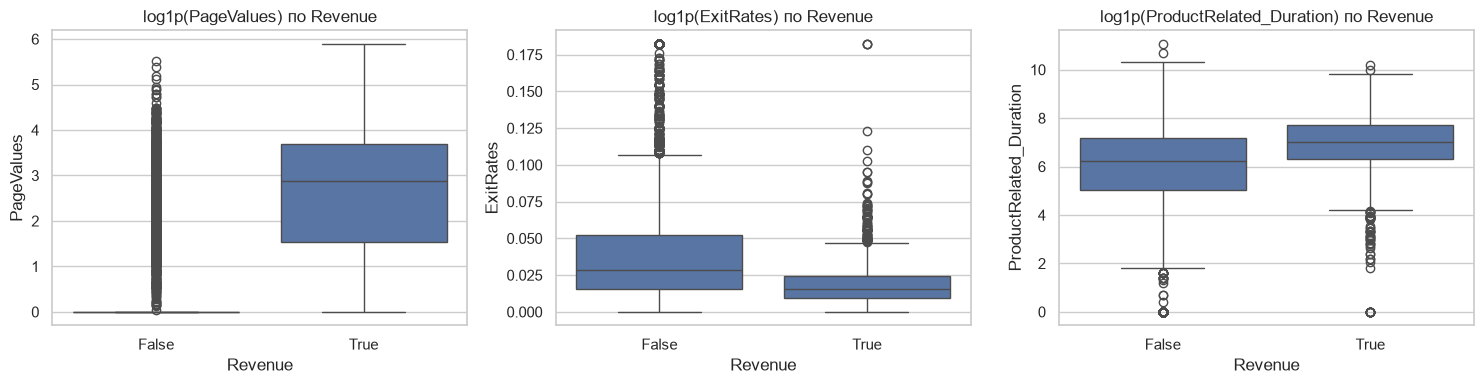

In [10]:
display(df.groupby(TARGET)[num_cols].mean().T)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['PageValues', 'ExitRates', 'ProductRelated_Duration']):
    sns.boxplot(x=df[TARGET], y=np.log1p(df[col]), ax=ax)
    ax.set_title(f'log1p({col}) по Revenue')
plt.tight_layout(); plt.show()

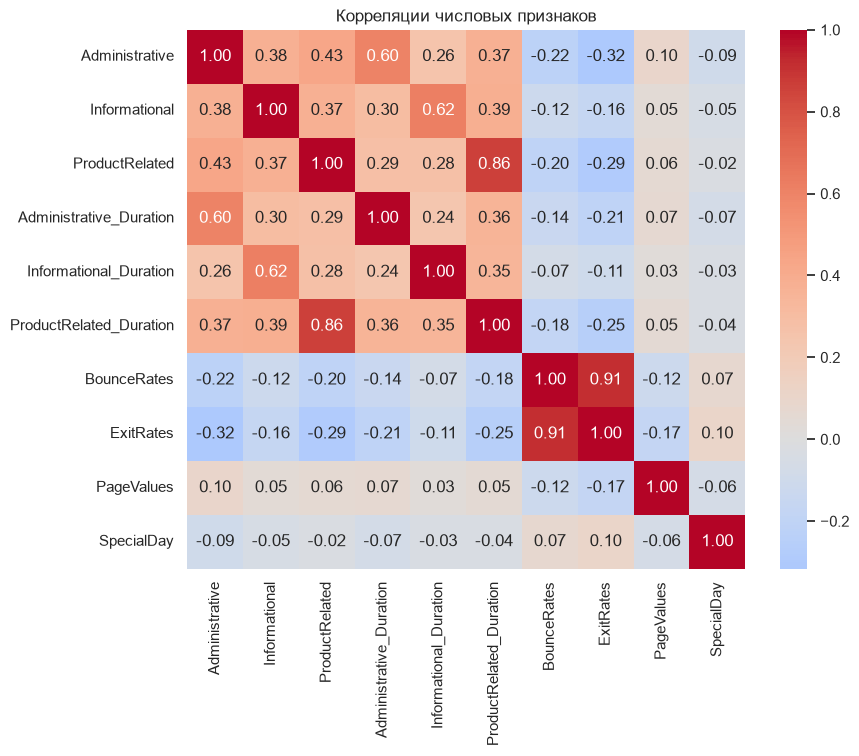

Пары с |r| > 0.8:
  ProductRelated — ProductRelated_Duration: 0.86
  BounceRates — ExitRates: 0.91


In [11]:
corr = df[num_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляции числовых признаков'); plt.show()

print('Пары с |r| > 0.8:')
for i, a in enumerate(num_cols):
    for b in num_cols[i + 1:]:
        if abs(corr.loc[a, b]) > 0.8:
            print(f'  {a} — {b}: {corr.loc[a, b]:.2f}')

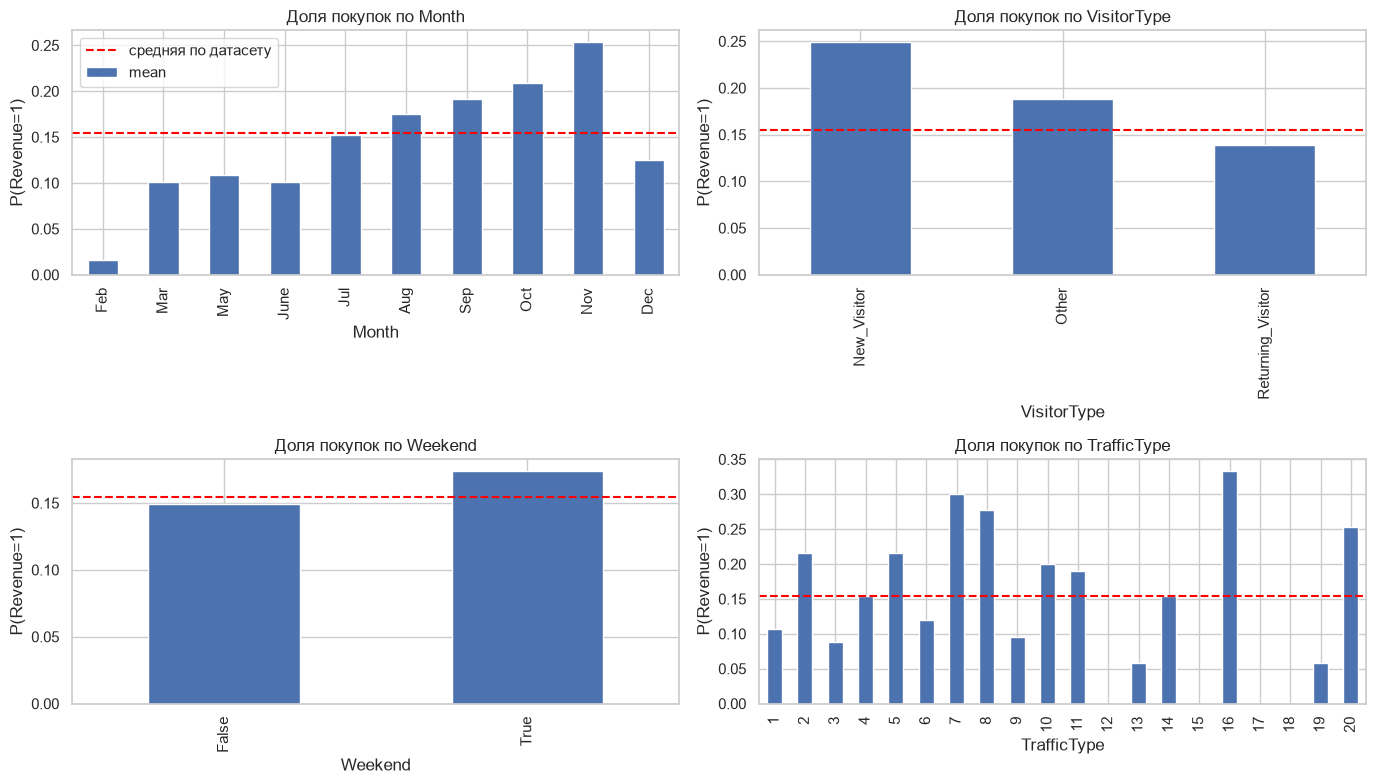

,mean,count
VisitorType,,
New_Visitor,0.249,1694
Other,0.188,85
Returning_Visitor,0.139,10551


In [12]:
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'June', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
base_rate = df[TARGET].mean()

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col in zip(axes.ravel(), ['Month', 'VisitorType', 'Weekend', 'TrafficType']):
    stats = df.groupby(col)[TARGET].agg(['mean', 'count'])
    if col == 'Month':
        stats = stats.reindex([m for m in month_order if m in stats.index])
    stats['mean'].plot(kind='bar', ax=ax, title=f'Доля покупок по {col}')
    ax.axhline(base_rate, color='red', ls='--', label='средняя по датасету')
    ax.set_ylabel('P(Revenue=1)')
axes[0, 0].legend()
plt.tight_layout(); plt.show()
display(df.groupby('VisitorType')[TARGET].agg(['mean', 'count']))

**Выводы по EDA** 

- Баланс классов:Классы несбалансированы: 84.5% False / 15.5% True (1908 покупок). Следовательно: accuracy неинформативна (базлайн «всегда False» = 84.5%), метрики — ROC-AUC / PR-AUC / F1; при обучении уместны class_weight/oversampling.
- Распределения: Сильная правосторонняя асимметрия (skew ≈ 2.0–7.6) и большая доля нулей до 90% (SpecialDay); в PageValues нулей 78%, в Informational_Duration 80%. Это значит: большинство значений маленькие, но есть редкие огромные («длинный хвост»). log1p сжимает хвост, чтобы линейная модель не «сходила с ума» на редких гигантах.
- Что отличает покупающие сессии от остальных: PageValues среднее 27.3 у покупателей против 2.0 у остальных, разница почти в 14 раз. Administrative_Duration, Informational_Duration, ProductRelated_Duration, ProductRelated выше в 1.6–1.9 раза. BounceRates и ExitRates: у покупателей они ниже (0.005 против 0.025 и 0.020 против 0.047), то есть покупатели реже «убегают» со страницы.
- Сильно коррелирующие признаки:
BounceRates и ExitRates: r = 0.91 (оба про «уход со страницы»);
ProductRelated и ProductRelated_Duration: 0.86;
Administrative и Administrative_Duration: 0.60;
Informational и Informational_Duration: 0.62.
Если два признака почти одинаковы, второй мало что добавляет, а у линейных моделей из-за этого веса становятся неустойчивыми
- Категории (месяц, тип посетителя, ...):
Месяц. Дольше всего покупают в ноябре (25.4%, почти 3000 сессий), потом октябрь (20.9%), сентябрь (19.2%), август (17.6%). Хуже всего февраль: всего 1.6%, но там и сессий лишь 184. В дополнение в выборке нет января и апреля.
Тип посетителя. Новые покупают чаще (24.9%), чем вернувшиеся (13.9%), хотя вернувшиеся составляют 86% сессий. «Other» (18.8%), но там всего 85 сессий.
Выходные. 17.4% против 14.9%: разница небольшая.
- Пропуски и дубликаты: пропусков нет, проверено. Дубликатов 125, и это не «шум». Причина их удалять другая: идентичные строки могли бы попасть и в train, и в test, и модель «знала» бы часть теста (утечка).

## 3. Подготовка данных

Решения и причины:
- **Дубликаты удаляем до разбиения**: одинаковые строки могли бы попасть и в train, и в test — это утечка.
- **Коды ОС, браузера, региона, типа трафика — категории**, а не числа (порядок кодов ничего не значит), поэтому one-hot.
- **Числа с тяжёлым хвостом и множеством нулей** (счётчики страниц, длительности, `PageValues`): для линейной модели `log1p` + стандартизация; деревьям масштаб не важен.
- **Масштабирование и кодирование — внутри `Pipeline`**, поэтому на каждой CV-итерации параметры считаются только по train-части (без утечки).
- **Test откладываем сразу и не трогаем до финальной оценки.** Все подборы (гиперпараметры, порог, k для отбора признаков) — только на train через кросс-валидацию.

In [27]:
df = df.drop_duplicates().reset_index(drop=True)
df['Weekend'] = df['Weekend'].astype(int)
df[cat_cols] = df[cat_cols].astype(str)

X = df.drop(columns=TARGET)
y = df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('train:', X_train.shape, 'test:', X_test.shape)
print('доля покупок train / test:', round(y_train.mean(), 3), '/', round(y_test.mean(), 3))

train: (9764, 17) test: (2441, 17)
доля покупок train / test: 0.156 / 0.156


In [28]:
skewed_cols = count_cols + dur_cols + ['PageValues']   # тяжёлый хвост + много нулей -> log1p
other_num_cols = ['BounceRates', 'ExitRates', 'SpecialDay']

def make_preprocessor(linear=True, drop=()):
    """linear=True: log1p + стандартизация (нужно логрегрессии); False: числа как есть (деревьям масштаб не важен).
    drop — список числовых признаков, которые нужно убрать (для эксперимента H4)."""
    skew = [c for c in skewed_cols if c not in drop]
    other = [c for c in other_num_cols if c not in drop]
    if linear:
        skew_tf = Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                            ('scale', StandardScaler())])
        other_tf = StandardScaler()
    else:
        skew_tf, other_tf = 'passthrough', 'passthrough'
    return ColumnTransformer([
        ('skew', skew_tf, skew),
        ('num', other_tf, other),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
        ('bin', 'passthrough', bin_cols),
    ], sparse_threshold=0)

# Кросс-валидация и метрики: стратифицированная, чтобы доля покупок была одинаковой в каждом фолде
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'accuracy': 'accuracy',
    'f1': make_scorer(f1_score, zero_division=0),
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision',
}

def cv_row(name, model, X, y):
    res = cross_validate(model, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    row = {'model': name}
    row.update({m: res[f'test_{m}'].mean() for m in scoring})
    row['roc_auc_std'] = res['test_roc_auc'].std()
    row['pr_auc_std'] = res['test_pr_auc'].std()
    return row

## 4. Базовые модели

Начинаем с **baseline** — глупой модели, с которой сравниваем всё остальное, — затем берём три разных семейства моделей с параметрами по умолчанию: линейную (LogReg), одно дерево и ансамбли (Random Forest, градиентный бустинг). Всё оцениваем кросс-валидацией на train.

In [29]:
models = {
    'Dummy': Pipeline([('prep', make_preprocessor(False)),
                       ('clf', DummyClassifier(strategy='most_frequent'))]),
    'LogReg': Pipeline([('prep', make_preprocessor(True)),
                        ('clf', LogisticRegression(max_iter=2000))]),
    'DecisionTree': Pipeline([('prep', make_preprocessor(False)),
                              ('clf', DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    'RandomForest': Pipeline([('prep', make_preprocessor(False)),
                              ('clf', RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE))]),
    'HistGB': Pipeline([('prep', make_preprocessor(False)),
                        ('clf', HistGradientBoostingClassifier(random_state=RANDOM_STATE))]),
}

cv_default = pd.DataFrame([cv_row(n, m, X_train, y_train) for n, m in models.items()]).set_index('model')
display(cv_default)

,accuracy,f1,precision,recall,roc_auc,pr_auc,roc_auc_std,pr_auc_std
model,,,,,,,,
Dummy,0.844,0.000,0.000,0.000,0.500,0.156,0.000,0.000
LogReg,0.893,0.617,0.705,0.550,0.912,0.683,0.008,0.021
DecisionTree,0.861,0.562,0.556,0.568,0.742,0.384,0.015,0.026
RandomForest,0.902,0.627,0.778,0.526,0.922,0.740,0.004,0.016
HistGB,0.900,0.648,0.720,0.590,0.929,0.742,0.006,0.022


In [16]:
# Проверка H1: accuracy vs F1
dummy = cv_default.loc['Dummy']
best = cv_default.drop('Dummy')['pr_auc'].idxmax()
b = cv_default.loc[best]
print(f"Accuracy: Dummy {dummy['accuracy']:.3f} vs {best} {b['accuracy']:.3f}  -> прирост {(b['accuracy'] - dummy['accuracy']) * 100:.1f} п.п.")
print(f"F1:       Dummy {dummy['f1']:.3f} vs {best} {b['f1']:.3f}  -> прирост {b['f1'] - dummy['f1']:.3f}")

Accuracy: Dummy 0.844 vs HistGB 0.900  -> прирост 5.6 п.п.
F1:       Dummy 0.000 vs HistGB 0.648  -> прирост 0.648


## 5. H2 — какие признаки важнее всего (часть 1: один признак за раз)

Для каждого числового признака обучаем бустинг **только на нём** и смотрим CV ROC-AUC. Это показывает, сколько информации несёт каждый признак сам по себе (0.5 = ничего).

,ROC-AUC (только этот признак)
PageValues,0.860
ExitRates,0.684
ProductRelated_Duration,0.654
ProductRelated,0.629
Administrative,0.619
BounceRates,0.616
Administrative_Duration,0.600
Informational,0.558
Informational_Duration,0.546
SpecialDay,0.538


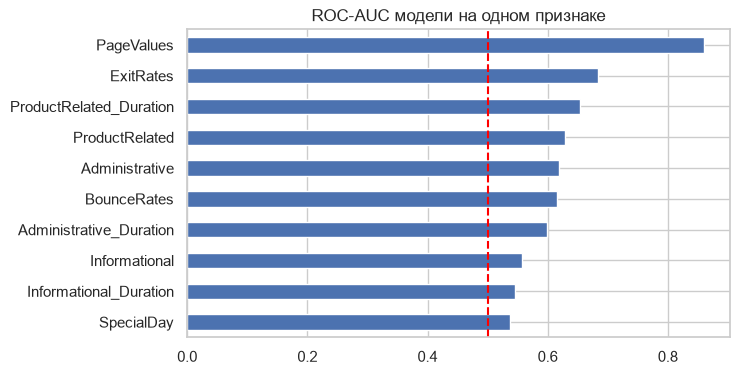

In [17]:
single = {}
for col in num_cols:
    single[col] = cross_val_score(HistGradientBoostingClassifier(random_state=RANDOM_STATE),
                                  X_train[[col]], y_train, cv=cv, scoring='roc_auc', n_jobs=-1).mean()
single = pd.Series(single).sort_values(ascending=False)
display(single.to_frame('ROC-AUC (только этот признак)'))
single.sort_values().plot(kind='barh', figsize=(7, 4), title='ROC-AUC модели на одном признаке')
plt.axvline(0.5, color='red', ls='--'); plt.show()

## 6. H5 — глубина дерева и переобучение

Кривая валидации: как меняется качество на train и на CV при росте `max_depth`. Расхождение кривых = переобучение.

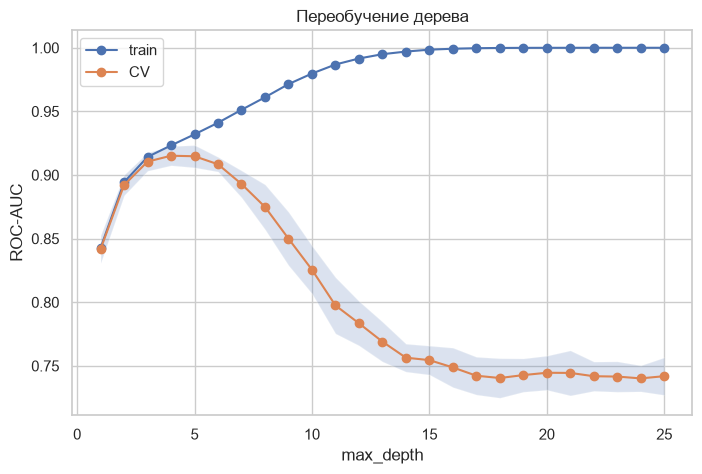

Лучшая глубина по CV: 4 (CV ROC-AUC = 0.915)
depth=15: train 0.999, CV 0.755, падение от пика 0.161
depth=25: train 1.000, CV 0.742, падение от пика 0.173


In [18]:
depths = list(range(1, 26))
tree_pipe = Pipeline([('prep', make_preprocessor(False)),
                      ('clf', DecisionTreeClassifier(random_state=RANDOM_STATE))])
tr, va = validation_curve(tree_pipe, X_train, y_train, param_name='clf__max_depth',
                          param_range=depths, cv=cv, scoring='roc_auc', n_jobs=-1)
tr_m, va_m, va_s = tr.mean(axis=1), va.mean(axis=1), va.std(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(depths, tr_m, 'o-', label='train')
plt.plot(depths, va_m, 'o-', label='CV')
plt.fill_between(depths, va_m - va_s, va_m + va_s, alpha=0.2)
plt.xlabel('max_depth'); plt.ylabel('ROC-AUC'); plt.legend(); plt.title('Переобучение дерева')
plt.show()

best_depth = depths[int(va_m.argmax())]
print(f'Лучшая глубина по CV: {best_depth} (CV ROC-AUC = {va_m.max():.3f})')
for d in (15, 25):
    print(f'depth={d}: train {tr_m[d - 1]:.3f}, CV {va_m[d - 1]:.3f}, падение от пика {va_m.max() - va_m[d - 1]:.3f}')

## 7. мультиколлинеарность (вне гипотез)

Находим пары признаков с |r| > 0.85 (по train), из каждой пары убираем тот признак, который слабее связан с таргетом, и сравниваем качество с полным набором.

In [19]:
CORR_THR = 0.85
corr_tr = X_train[num_cols].corr().abs()
target_corr = X_train[num_cols].apply(lambda s: abs(np.corrcoef(s, y_train)[0, 1]))
pairs = [(a, b) for i, a in enumerate(num_cols) for b in num_cols[i + 1:] if corr_tr.loc[a, b] > CORR_THR]
to_drop = sorted({a if target_corr[a] < target_corr[b] else b for a, b in pairs})
print('Пары с |r| >', CORR_THR, ':')
for a, b in pairs:
    print(f'  {a} — {b}: r = {corr_tr.loc[a, b]:.2f}')
print('Удаляем (слабее связан с таргетом):', to_drop)

rows = []
for label, drop in [('все признаки', ()), ('без ' + ', '.join(to_drop), tuple(to_drop))]:
    for name, clf, linear in [('LogReg', LogisticRegression(max_iter=2000), True),
                              ('DecisionTree', DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE), False)]:
        pipe = Pipeline([('prep', make_preprocessor(linear, drop)), ('clf', clf)])
        r = cv_row(name, pipe, X_train, y_train)
        rows.append({'модель': name, 'набор': label, 'roc_auc': r['roc_auc'], 'roc_auc_std': r['roc_auc_std'], 'pr_auc': r['pr_auc']})
display(pd.DataFrame(rows))

Пары с |r| > 0.85 :
  ProductRelated — ProductRelated_Duration: r = 0.85
  BounceRates — ExitRates: r = 0.90
Удаляем (слабее связан с таргетом): ['BounceRates', 'ProductRelated_Duration']


,модель,набор,roc_auc,roc_auc_std,pr_auc
0,LogReg,все признаки,0.912,0.008,0.683
1,DecisionTree,все признаки,0.915,0.008,0.684
2,LogReg,"без BounceRates, ProductRelated_Duration",0.912,0.008,0.683
3,DecisionTree,"без BounceRates, ProductRelated_Duration",0.912,0.007,0.651


In [20]:
# Коэффициенты логрегрессии для скоррелированных признаков (на полном наборе)
if pairs:
    pipe_full = Pipeline([('prep', make_preprocessor(True)),
                          ('clf', LogisticRegression(max_iter=2000))]).fit(X_train, y_train)
    names = pipe_full['prep'].get_feature_names_out()
    coefs = pd.Series(pipe_full['clf'].coef_[0], index=names)
    involved = sorted({c for p in pairs for c in p})
    display(coefs[[n for n in names if n.split('__', 1)[1] in involved]].to_frame('коэффициент'))

,коэффициент
skew__ProductRelated,0.123
skew__ProductRelated_Duration,0.026
num__BounceRates,-0.190
num__ExitRates,-0.429


## 8. Подбор гиперпараметров

`RandomizedSearchCV` по 5-fold CV на train, метрика — **PR-AUC** (average precision): она не зависит от порога и подходит для несбалансированных классов. Test здесь не используется.

Замечание: лучший CV-скор после перебора слегка оптимистичен (мы выбрали максимум из шумных оценок) — честная оценка будет на test.

In [21]:
N_ITER = 20

base_pipes = {
    'LogReg': Pipeline([('prep', make_preprocessor(True)), ('clf', LogisticRegression(max_iter=3000))]),
    'DecisionTree': Pipeline([('prep', make_preprocessor(False)), ('clf', DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    'RandomForest': Pipeline([('prep', make_preprocessor(False)), ('clf', RandomForestClassifier(random_state=RANDOM_STATE))]),
    'HistGB': Pipeline([('prep', make_preprocessor(False)), ('clf', HistGradientBoostingClassifier(random_state=RANDOM_STATE))]),
}
param_dists = {
    'LogReg': {'clf__C': loguniform(1e-3, 1e2), 'clf__class_weight': [None, 'balanced']},
    'DecisionTree': {'clf__max_depth': randint(2, 15), 'clf__min_samples_leaf': randint(1, 50),
                     'clf__criterion': ['gini', 'entropy']},
    'RandomForest': {'clf__n_estimators': randint(100, 400), 'clf__max_depth': [None, 5, 10, 15],
                     'clf__min_samples_leaf': randint(1, 20), 'clf__max_features': ['sqrt', 0.3]},
    'HistGB': {'clf__learning_rate': loguniform(0.01, 0.3), 'clf__max_depth': [None, 3, 5, 8],
               'clf__max_leaf_nodes': randint(8, 64), 'clf__l2_regularization': loguniform(1e-3, 10),
               'clf__min_samples_leaf': randint(10, 100)},
}

searches = {}
for name, pipe in base_pipes.items():
    s = RandomizedSearchCV(pipe, param_dists[name], n_iter=N_ITER, scoring='average_precision',
                           cv=cv, n_jobs=-1, random_state=RANDOM_STATE)
    s.fit(X_train, y_train)
    searches[name] = s
    print(f'{name:13s} CV PR-AUC = {s.best_score_:.3f}   {s.best_params_}')

best_name = max(searches, key=lambda n: searches[n].best_score_)
print('\nЛучшая модель по CV PR-AUC:', best_name)

LogReg        CV PR-AUC = 0.685   {'clf__C': np.float64(0.0745934328572655), 'clf__class_weight': None}
DecisionTree  CV PR-AUC = 0.716   {'clf__criterion': 'gini', 'clf__max_depth': 10, 'clf__min_samples_leaf': 39}
RandomForest  CV PR-AUC = 0.756   {'clf__max_depth': None, 'clf__max_features': 0.3, 'clf__min_samples_leaf': 8, 'clf__n_estimators': 251}
HistGB        CV PR-AUC = 0.755   {'clf__l2_regularization': np.float64(0.5456725485601477), 'clf__learning_rate': np.float64(0.044684675025045834), 'clf__max_depth': 5, 'clf__max_leaf_nodes': 51, 'clf__min_samples_leaf': 17}

Лучшая модель по CV PR-AUC: RandomForest


## 9. H3 — отбор признаков (`SelectKBest`)

Отбор стоит **внутри Pipeline** — значит, на каждой CV-итерации признаки выбираются только по train-части фолда. Если отобрать признаки по всему train до кросс-валидации, информация о валидационных фолдах «просочится» в отбор.

roc_auc        pr_auc       
model  HistGB LogReg HistGB LogReg
k                                 
3       0.893  0.882  0.670  0.653
5       0.895  0.881  0.691  0.660
8       0.917  0.903  0.727  0.676
12      0.918  0.907  0.731  0.681
20      0.925  0.912  0.733  0.683
all     0.929  0.912  0.742  0.683

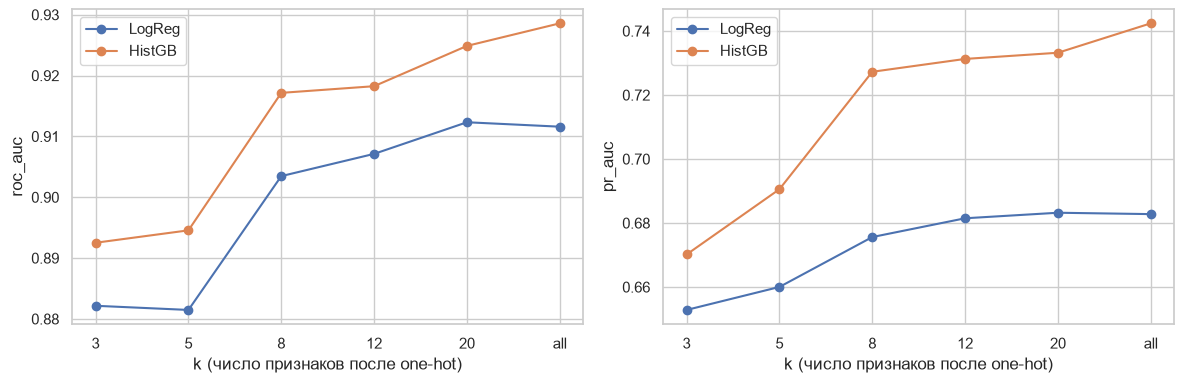

k=8: ['skew__Administrative', 'skew__ProductRelated', 'skew__Administrative_Duration', 'skew__ProductRelated_Duration', 'skew__PageValues', 'num__BounceRates', 'num__ExitRates', 'cat__Month_Nov']


In [22]:
ks = [3, 5, 8, 12, 20, 'all']
rows = []
for name, clf in [('LogReg', LogisticRegression(max_iter=2000)),
                  ('HistGB', HistGradientBoostingClassifier(random_state=RANDOM_STATE))]:
    for k in ks:
        steps = [('prep', make_preprocessor(True))]
        if k != 'all':
            steps.append(('select', SelectKBest(f_classif, k=k)))
        steps.append(('clf', clone(clf)))
        r = cv_row(name, Pipeline(steps), X_train, y_train)
        rows.append({'model': name, 'k': str(k), 'roc_auc': r['roc_auc'], 'pr_auc': r['pr_auc']})
sel = pd.DataFrame(rows)
order = [str(k) for k in ks]
tab = sel.pivot(index='k', columns='model', values=['roc_auc', 'pr_auc']).loc[order]
display(tab)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ['roc_auc', 'pr_auc']):
    for name in ['LogReg', 'HistGB']:
        sub = sel[sel.model == name].set_index('k').loc[order]
        ax.plot(order, sub[metric], 'o-', label=name)
    ax.set_xlabel('k (число признаков после one-hot)'); ax.set_ylabel(metric); ax.legend()
plt.tight_layout(); plt.show()

# Какие признаки выбрал SelectKBest при k=8 (обучено только на train)
prep = make_preprocessor(True).fit(X_train, y_train)
selector = SelectKBest(f_classif, k=8).fit(prep.transform(X_train), y_train)
print('k=8:', list(np.array(prep.get_feature_names_out())[selector.get_support()]))

## 10. Подбор порога классификации (только train)

Для каждой подобранной модели получаем **out-of-fold** вероятности на train (каждый объект предсказан моделью, которая его не видела) и выбираем порог, максимизирующий F1 по классу «покупка». Test по-прежнему не трогаем.

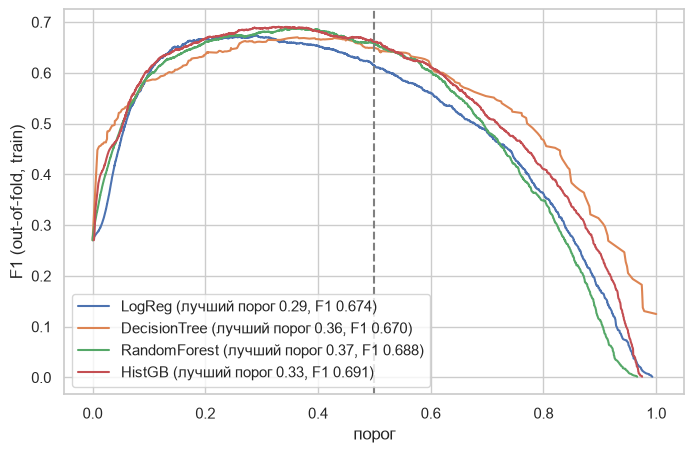

In [23]:
thr_by_model = {}
fig, ax = plt.subplots(figsize=(8, 5))
for name, s in searches.items():
    oof = cross_val_predict(clone(s.best_estimator_), X_train, y_train, cv=cv,
                            method='predict_proba', n_jobs=-1)[:, 1]
    prec, rec, thr = precision_recall_curve(y_train, oof)
    f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    thr_by_model[name] = float(thr[f1s.argmax()])
    ax.plot(thr, f1s, label=f'{name} (лучший порог {thr_by_model[name]:.2f}, F1 {f1s.max():.3f})')
ax.axvline(0.5, color='gray', ls='--')
ax.set_xlabel('порог'); ax.set_ylabel('F1 (out-of-fold, train)'); ax.legend()
plt.show()

## 11. Финальная оценка на test (H1, H2, H4, порог)

Единственное место, где используется test. Модели уже выбраны и обучены на train, пороги подобраны на train.

In [24]:
def test_row(name, model, thr=0.5):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= thr).astype(int)
    return {'model': name, 'порог': thr,
            'accuracy': accuracy_score(y_test, pred),
            'precision': precision_score(y_test, pred, zero_division=0),
            'recall': recall_score(y_test, pred, zero_division=0),
            'f1': f1_score(y_test, pred, zero_division=0),
            'roc_auc': roc_auc_score(y_test, proba),
            'pr_auc': average_precision_score(y_test, proba)}

dummy_fit = clone(models['Dummy']).fit(X_train, y_train)
rows = [test_row('Dummy', dummy_fit)]
for name, s in searches.items():
    rows.append(test_row(name, s.best_estimator_, 0.5))
    rows.append(test_row(name + ' (порог подобран)', s.best_estimator_, thr_by_model[name]))
final = pd.DataFrame(rows).set_index('model')
display(final)

,порог,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,,
Dummy,0.500,0.844,0.000,0.000,0.000,0.500,0.156
LogReg,0.500,0.900,0.713,0.599,0.651,0.922,0.697
LogReg (порог подобран),0.291,0.889,0.625,0.720,0.669,0.922,0.697
DecisionTree,0.500,0.900,0.714,0.602,0.653,0.913,0.678
DecisionTree (порог подобран),0.364,0.890,0.632,0.715,0.671,0.913,0.678
RandomForest,0.500,0.907,0.744,0.615,0.673,0.932,0.757
RandomForest (порог подобран),0.366,0.900,0.670,0.712,0.690,0.932,0.757
HistGB,0.500,0.904,0.726,0.618,0.668,0.937,0.758
HistGB (порог подобран),0.331,0.898,0.657,0.736,0.694,0.937,0.758


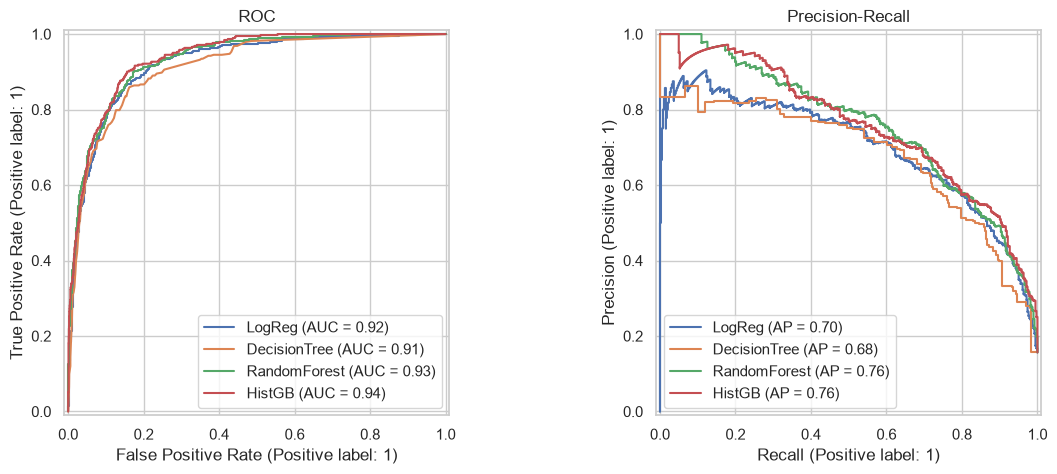

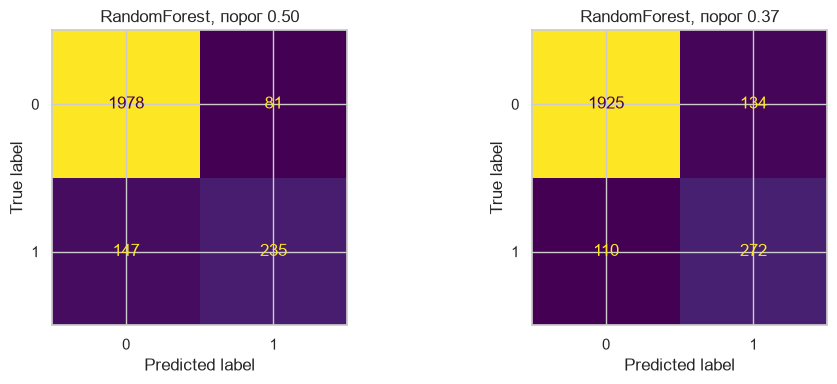

In [25]:
# Кривые ROC и Precision-Recall на test
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, s in searches.items():
    RocCurveDisplay.from_estimator(s.best_estimator_, X_test, y_test, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_estimator(s.best_estimator_, X_test, y_test, name=name, ax=axes[1])
axes[0].set_title('ROC'); axes[1].set_title('Precision-Recall')
plt.show()

# Матрицы ошибок лучшей модели: порог 0.5 и подобранный
best_model = searches[best_name].best_estimator_
proba = best_model.predict_proba(X_test)[:, 1]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, thr in zip(axes, [0.5, thr_by_model[best_name]]):
    ConfusionMatrixDisplay.from_predictions(y_test, (proba >= thr).astype(int), ax=ax, colorbar=False)
    ax.set_title(f'{best_name}, порог {thr:.2f}')
plt.tight_layout(); plt.show()

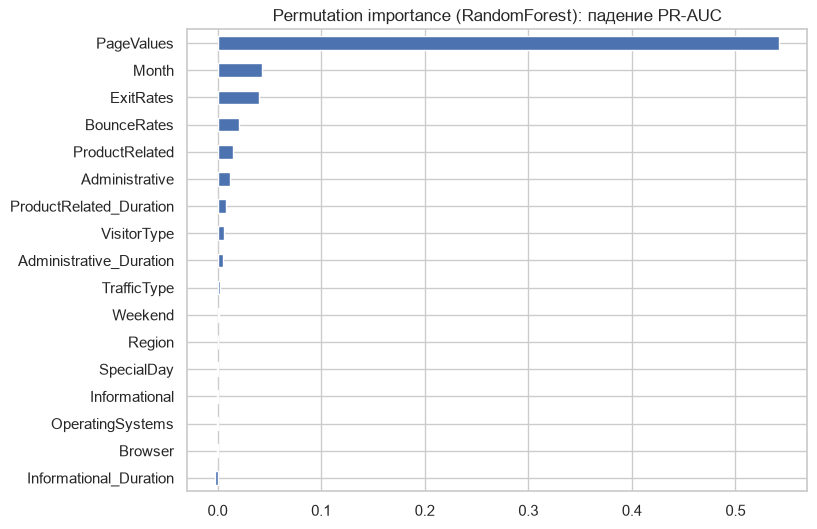

,падение PR-AUC
PageValues,0.542
Month,0.043
ExitRates,0.040
BounceRates,0.021
ProductRelated,0.015
Administrative,0.012
ProductRelated_Duration,0.008
VisitorType,0.006


In [26]:
# H2 (часть 2): permutation importance лучшей модели на test — насколько падает PR-AUC, если перемешать признак
pi = permutation_importance(best_model, X_test, y_test, scoring='average_precision',
                            n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
imp.plot(kind='barh', figsize=(8, 6), title=f'Permutation importance ({best_name}): падение PR-AUC')
plt.show()
display(imp.sort_values(ascending=False).head(8).to_frame('падение PR-AUC'))

## 12. Выводы по гипотезам

<strong>H1 (accuracy обманывает).</strong> Вердикт: подтвердилась. Числа: Dummy accuracy = 0.844, F1 = 0.000; лучшая модель (HistGB по CV PR-AUC) accuracy = 0.900, F1 = 0.648; на test лучшая RandomForest: accuracy 0.907, F1 0.673 (0.694 при подобранном пороге). Почему: 84.5% сессий без покупки, поэтому «никто не купит» угадывает 5 сессий из 6 (accuracy 0.844) при нулевой способности находить покупателей (F1 = 0, PR-AUC = 0.156 = базовая доля покупок). Обученная модель поднимает accuracy лишь на ~6 п.п. (0.844 → 0.900–0.907), зато F1 — с 0 до 0.65–0.69: accuracy измеряет в основном угадывание большинства и скрывает реальную разницу моделей, поэтому целевые метрики — PR-AUC и F1.

<strong>H2 (PageValues).</strong> Вердикт: подтвердилась. Числа: ROC-AUC на одном признаке = 0.860 (порог ≥ 0.85 выполнен); место в permutation importance = 1-е (падение PR-AUC при перемешивании 0.542, следующий признак Month — 0.043, разрыв в 12 раз). Почему: PageValues — денежная ценность просмотренных страниц; ненулевая только когда сессия дошла до «коммерческих» страниц (корзина/оформление): у 78% сессий ноль, у покупателей среднее 27.3 против 2.0 у остальных (~×14). Это почти прямой «маркер» покупки: модель на одном этом признаке даёт ROC-AUC 0.86, а его перемешивание в полной модели роняет PR-AUC вдвое.

<strong>H3 (хватит 8 признаков).</strong> Вердикт: частично. Числа: k=8 vs all: LogReg ROC-AUC 0.903 vs 0.912 (падение 0.009 < 0.01 — условие выполнено), HistGB 0.917 vs 0.929 (падение 0.012 > 0.01 — условие не выполнено); по PR-AUC падения 0.007 и 0.015 соответственно. Почему: при k=8 SelectKBest отбирает все признаки с сильным одиночным сигналом (skew__PageValues, skew__ProductRelated и skew__ProductRelated_Duration, skew__Administrative и skew__Administrative_Duration, num__BounceRates, num__ExitRates, cat__Month_Nov) — линейной модели этого хватает. Бустинг же на полном наборе дополнительно выжимает слабые совместные эффекты оставшихся признаков (другие месяцы, VisitorType, Weekend), поэтому падение у HistGB чуть выше 0.01. Вывод: 8 признаков достаточно для LogReg, но не для HistGB.

<strong>H4 (бустинг/RF лучше LogReg).</strong> Вердикт: подтвердилась. Числа: PR-AUC LogReg = 0.685 (CV после подбора, без подбора 0.683), лучшая нелинейная = RandomForest 0.756 (HistGB 0.755 рядом), разница ≈ 0.07 ≥ 0.03; на test: 0.697 vs 0.757/0.758. Почему: зависимость покупки от признаков нелинейна и с взаимодействиями (порог по PageValues, сезонность Month, «вовлечённость × уход»), деревья и ансамбли ловят их сами, а нули и тяжёлые хвосты им не мешают; LogReg даже после log1p не хватает гибкости. Оговорка: RF и HistGB статистически неразличимы (разница CV 0.001 при std по фолдам 0.016–0.022), поэтому честная формулировка — «оба ансамбля лучше LogReg», а не «бустинг лучше RF».

<strong>H5 (лучшая глубина дерева по CV лежит в 3–8).</strong> Вердикт: подтвердилась. Числа: лучшая глубина = 4 (CV ROC-AUC 0.915 — лежит в 3–8); при depth = 15: train = 0.999 (> 0.98), CV = 0.755 (падение от пика 0.161 ≥ 0.03); при depth = 25: train = 1.000, CV = 0.742 (падение 0.173). Почему: неограниченное дерево запоминает шум train (train ROC-AUC → 1), а обобщающая способность растёт до глубины ~4 и затем деградирует — классическое переобучение; его мера и есть расхождение кривых train/CV после пика.

### Наблюдения вне гипотез 
- <strong>Мультиколлинеарность (раздел 7):</strong> пары |r| > 0.85 по train — ProductRelated — ProductRelated_Duration (0.85) и BounceRates — ExitRates (0.90). Удаление слабейшего признака из пары не меняет LogReg (ROC-AUC 0.912 / 0.912, PR-AUC 0.683 / 0.683); у дерева ROC-AUC 0.915 → 0.912, PR-AUC 0.684 → 0.651: для сплитов пары не 100%-дубликаты. У LogReg коэффициенты внутри пары «размазываются» (ExitRates −0.429 vs BounceRates −0.190; ProductRelated 0.123 vs Duration 0.026) — мультиколлинеарность здесь проблема интерпретации, а не качества.
- <strong>Порог (раздел 10):</strong> подобран по out-of-fold F1 на train (LogReg 0.29, DecisionTree 0.36, RandomForest 0.37, HistGB 0.33). На test F1 растёт: RandomForest 0.673 → 0.690, HistGB 0.668 → 0.694 (recall 0.618 → 0.736) ценой небольшого падения precision (0.726 → 0.657) и accuracy (0.904 → 0.898) — осознанный сдвиг баланса в сторону полноты при дисбалансе 15.6%.

### Общие выводы
- <strong>Лучшая модель и стабильность:</strong> RandomForest и HistGB статистически неразличимы (CV PR-AUC 0.756 / 0.755, std по фолдам 0.016 / 0.022; на test PR-AUC 0.757 / 0.758, ROC-AUC 0.932 / 0.937). Формально лучшая по CV — RandomForest, её и оставляем финальной. Оценка стабильна: std roc_auc по фолдам 0.004–0.008, разница CV → test ≤ 0.01 (HistGB roc_auc 0.929 → 0.937) — переобучения на test нет; лёгкий оптимизм лучшего CV-скора после перебора ожидаем и оговорён в разделе 8.
- <strong>Что бы сделал дальше:</strong> (1) временна́я валидация (обучение на ранних месяцах, тест на поздних) — сильная сезонность (Nov 25.4% покупок против Feb 1.6%), случайный split может завышать качество; (2) калибровка вероятностей и порог по бизнес-стоимости FP/FN; (3) признаки-отношения (время на страницу); (4) grouped split по пользователям, если появятся id; (5) увеличить n_iter RandomizedSearchCV для HistGB (20 итераций мало для 6-мерного пространства).
- <strong>Ограничения:</strong> один датасет и один сезон (Feb–Dec, без Jan/Apr); нет id пользователей — сессии одного человека могут попасть и в train, и в test (оптимистичная оценка); 125 дубликатов удалены, но похожие сессии остались; признаки — агрегаты сессии без последовательности действий; permutation importance посчитан на test и используется только для интерпретации, не для решений.